# 04 - Post-session analysis (single subject, single session)

Loads one recorded session folder produced by the daemon (`studies/<SUBJECT>/<SESSION_ID>/`) and renders the five figures the thesis chapter needs for a single session.

Works the same on **sim** runs (driven by `scripts/run_smoke_session.py`) and **real-hardware** runs (driven by the UI's session-create form with `eeg_source=biolistener`). For sim runs, `raw_eeg.csv` is recorded the same way it is for hardware - same file format, same downstream pipeline.

Set `SUBJECT` and `SESSION_ID` in the setup cell, run-all, and the figures fall out.

## Setup - point at one session

If `SESSION_ID` is `None` the notebook picks the most-recently-modified non-empty session under `SUBJECT`. Override either constant by hand to pin a specific run.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if Path.cwd().name == 'notebooks' or Path.cwd().name == 'future':
    while Path.cwd().name in ('notebooks', 'future'):
        os.chdir(Path.cwd().parent)
print('cwd:', Path.cwd())

# === EDIT THESE TWO ===
SUBJECT = 'SMOKE'                 # 'SM' for the researcher, 'SMOKE' for sim smoke-test
SESSION_ID = None              # None = auto-pick most-recent non-empty folder
# =======================

STUDIES_ROOT = Path('studies')

def pick_session(subject: str, session_id):
    """Either honor the explicit id, or auto-pick the latest non-empty folder.
    `SMOKE` was the smoke-script's parent, so we also peek under SMOKE_REAL_LIKE/
    where the in-process smoke session lands."""
    roots = [STUDIES_ROOT / subject]
    if subject == 'SMOKE':
        roots.insert(0, STUDIES_ROOT / 'SMOKE_REAL_LIKE' / 'SMOKE')
    if session_id is not None:
        for root in roots:
            cand = root / session_id
            if cand.exists():
                return cand
        raise FileNotFoundError(f'No {subject}/{session_id} under any of {roots}')
    candidates = []
    for root in roots:
        if not root.exists():
            continue
        for f in root.iterdir():
            if (f / 'features.parquet').exists():
                candidates.append(f)
    if not candidates:
        raise FileNotFoundError(f'No non-empty session folders for subject={subject!r}')
    return max(candidates, key=lambda p: p.stat().st_mtime)

SESSION = pick_session(SUBJECT, SESSION_ID)
SESSION_ID = SESSION.name
print(f'Loaded session: {SESSION}')
print(f'  files: {sorted(f.name for f in SESSION.iterdir())}')

feats   = pd.read_parquet(SESSION / 'features.parquet')
stim    = pd.read_parquet(SESSION / 'stim_log.parquet')
actions = (pd.read_parquet(SESSION / 'agent_action.parquet')
           if (SESSION / 'agent_action.parquet').exists() else None)
safety  = []
if (SESSION / 'safety_events.jsonl').exists():
    with (SESSION / 'safety_events.jsonl').open() as fh:
        safety = [json.loads(line) for line in fh if line.strip()]
protocol = json.loads((SESSION / 'protocol.json').read_text())
seed_doc = (json.loads((SESSION / 'audio_seed.json').read_text())
            if (SESSION / 'audio_seed.json').exists() else {})

# Convert to seconds-since-start for plotting
for df in (feats, stim):
    df['t_s'] = df['t_ms'] / 1000.0
if actions is not None:
    actions['t_s'] = actions['t_ms'] / 1000.0
duration_s = max(feats['t_s'].max(), stim['t_s'].max())

print()
print(f'  protocol:      {protocol.get("protocol")}')
print(f'  eeg_source:    {protocol.get("eeg_source")}')
print(f'  mask_target:   {protocol.get("mask_target")}')
print(f'  audio_enabled: {protocol.get("audio_enabled")}')
print(f'  duration:      {duration_s:.1f} s  ·  {len(feats)} feature ticks')
print(f'  safety events: {len(safety)}')
# sim_meta layout differs by session kind: sim runs carry the randomized
# subject params (alpha_hz / responder / cortical_gain); real-hardware runs
# carry only {"source": eeg_source_spec}. Handle both without crashing on
# the missing keys.
sm = seed_doc.get('sim_meta') or {}
if sm.get('alpha_hz') is not None:
    print(f'  sim subject:   α_hz={sm["alpha_hz"]:.2f} responder={sm.get("responder")} '
          f'gain={sm.get("cortical_gain", 0):.0f}')
elif sm.get('source'):
    print(f'  hw source:     {sm["source"]}')

cwd: .
Loaded session: studies/SMOKE_REAL_LIKE/SMOKE/e48fd75e84e2
  files: ['agent_action.parquet', 'audio_seed.json', 'features.parquet', 'protocol.json', 'raw_eeg.csv', 'safety_events.jsonl', 'stim_log.parquet']

  protocol:      rl_agent
  eeg_source:    sim
  mask_target:   virtual
  audio_enabled: None
  duration:      58.2 s  ·  233 feature ticks
  safety events: 693
  sim subject:   α_hz=11.37 responder=moderate gain=241


## 1. Headline plot - closed-loop overlay (the figure the thesis chapter opens with)

Three stacked panels sharing the time axis:
1. **Strobe Hz** commanded by the agent (post-safety-clamp). The descent from the α-cap into θ is the closed-loop control behaviour.
2. **θ/α ratio** observed in EEG. The biomarker that should rise as the agent succeeds.
3. **PLV strobe→EEG** + **restfulness**. Auxiliary corroboration that the brain is actually entraining.

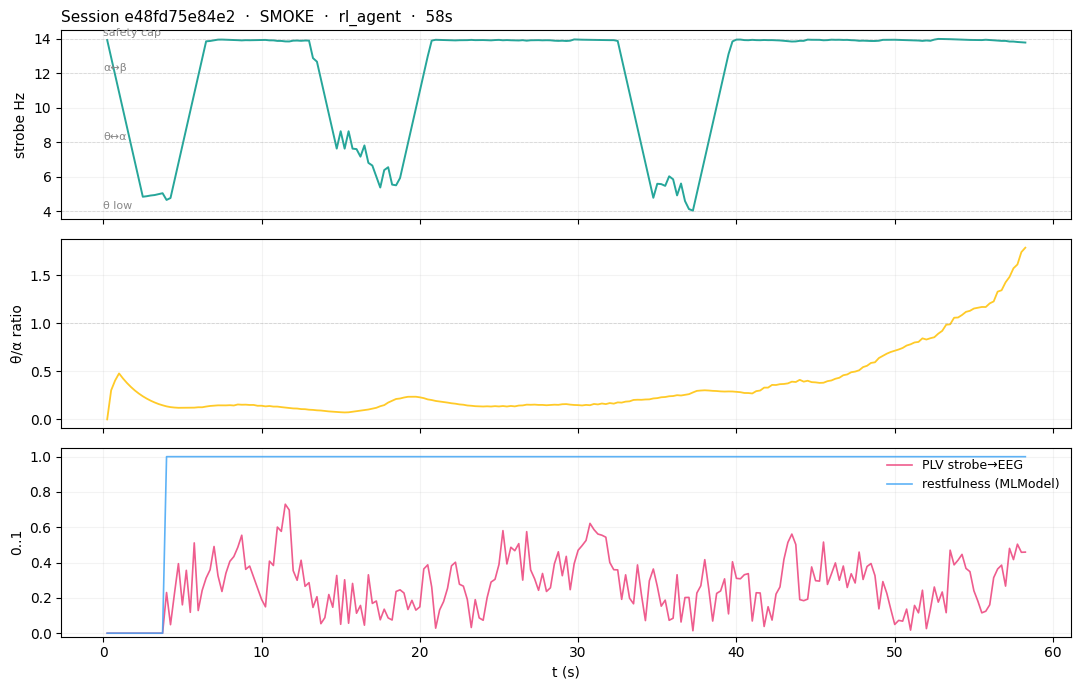


Final 30 s averages (steady-state behaviour):
  commanded strobe Hz:  12.45  (4.05..13.98)
  θ/α ratio:             0.53  (start: 0.19)
  PLV strobe→EEG:        0.29
  restfulness:           1.00


In [2]:
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True,
                          gridspec_kw={'height_ratios': [1, 1, 1]})

# Panel 1: commanded strobe frequency. Mark the safety-bound annotations.
ax = axes[0]
ax.plot(stim['t_s'], stim['mask_freq_hz'], color='#26A69A', lw=1.4)
for hz, label in [(4, 'θ low'), (8, 'θ↔α'), (12, 'α↔β'), (14, 'safety cap')]:
    ax.axhline(hz, color='#888', alpha=0.25, lw=0.6, linestyle='--')
    ax.text(0, hz + 0.15, label, color='#888', fontsize=8)
ax.set_ylabel('strobe Hz')
ax.set_title(f'Session {SESSION_ID}  ·  {SUBJECT}  ·  {protocol.get("protocol")}  ·  '
             f'{duration_s:.0f}s', loc='left', fontsize=11)
ax.grid(alpha=0.15)

# Panel 2: θ/α biomarker.
ax = axes[1]
ax.plot(feats['t_s'], feats['theta_alpha_ratio'], color='#FFCA28', lw=1.3)
ax.axhline(1.0, color='#888', alpha=0.3, lw=0.6, linestyle='--')
ax.set_ylabel('θ/α ratio')
ax.grid(alpha=0.15)

# Panel 3: PLV (entrainment proxy) + RESTFULNESS (BrainFlow MLModel).
ax = axes[2]
ax.plot(feats['t_s'], feats['plv_strobe'], color='#EC407A', lw=1.2,
        label='PLV strobe→EEG', alpha=0.85)
ax.plot(feats['t_s'], feats['restfulness'], color='#42A5F5', lw=1.2,
        label='restfulness (MLModel)', alpha=0.85)
ax.set_ylim(-0.02, 1.05)
ax.set_ylabel('0..1')
ax.set_xlabel('t (s)')
ax.legend(loc='upper right', frameon=False, fontsize=9)
ax.grid(alpha=0.15)

fig.tight_layout(); plt.show()

# Punchline numbers, lifted into the thesis caption verbatim.
tail = feats[feats['t_s'] >= duration_s - 30]
stim_tail = stim[stim['t_s'] >= duration_s - 30]
print(f'\nFinal 30 s averages (steady-state behaviour):')
print(f'  commanded strobe Hz:  {stim_tail["mask_freq_hz"].mean():5.2f}  '
      f'({stim_tail["mask_freq_hz"].min():.2f}..{stim_tail["mask_freq_hz"].max():.2f})')
print(f'  θ/α ratio:            {tail["theta_alpha_ratio"].mean():5.2f}  (start: '
      f'{feats["theta_alpha_ratio"].head(40).mean():.2f})')
print(f'  PLV strobe→EEG:       {tail["plv_strobe"].mean():5.2f}')
print(f'  restfulness:          {tail["restfulness"].mean():5.2f}')

## 2. Band-power evolution (log scale)

All five reported bands on one axis, log-y. Same y-units across bands (BrainFlow band powers), so cross-band relative magnitudes are meaningful. Sleep onset = α drops, θ rises (the two lines should cross), spindle σ stays low until N2.

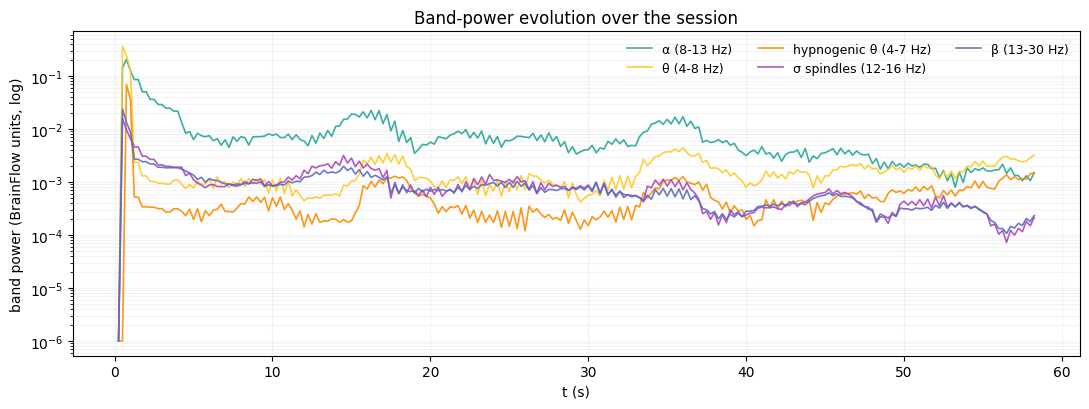

In [3]:
fig, ax = plt.subplots(figsize=(11, 4.2))
BAND_PLOT = [
    ('alpha_pwr',            '#26A69A', 'α (8-13 Hz)'),
    ('theta_pwr',            '#FFCA28', 'θ (4-8 Hz)'),
    ('hypnagogic_theta_pwr', '#FB8C00', 'hypnogenic θ (4-7 Hz)'),
    ('sigma_pwr',            '#AB47BC', 'σ spindles (12-16 Hz)'),
    ('beta_pwr',             '#5C6BC0', 'β (13-30 Hz)'),
]
for col, color, label in BAND_PLOT:
    ax.plot(feats['t_s'], feats[col].clip(lower=1e-6), color=color,
            lw=1.2, label=label, alpha=0.9)
ax.set_yscale('log')
ax.set_xlabel('t (s)')
ax.set_ylabel('band power (BrainFlow units, log)')
ax.legend(loc='upper right', frameon=False, ncol=3, fontsize=9)
ax.grid(alpha=0.15, which='both')
ax.set_title('Band-power evolution over the session')
fig.tight_layout(); plt.show()

## 3. Safety-overlay - what the policy WANTED vs what the supervisor LET THROUGH

Two lines per axis (frequency, brightness): the policy's pre-clamp request and the supervisor's post-clamp commanded value. **The shaded delta is the supervisor's contribution per tick.** A zero delta means the policy is operating inside the safe envelope on its own; visible deltas correspond to the safety_events table at the bottom.

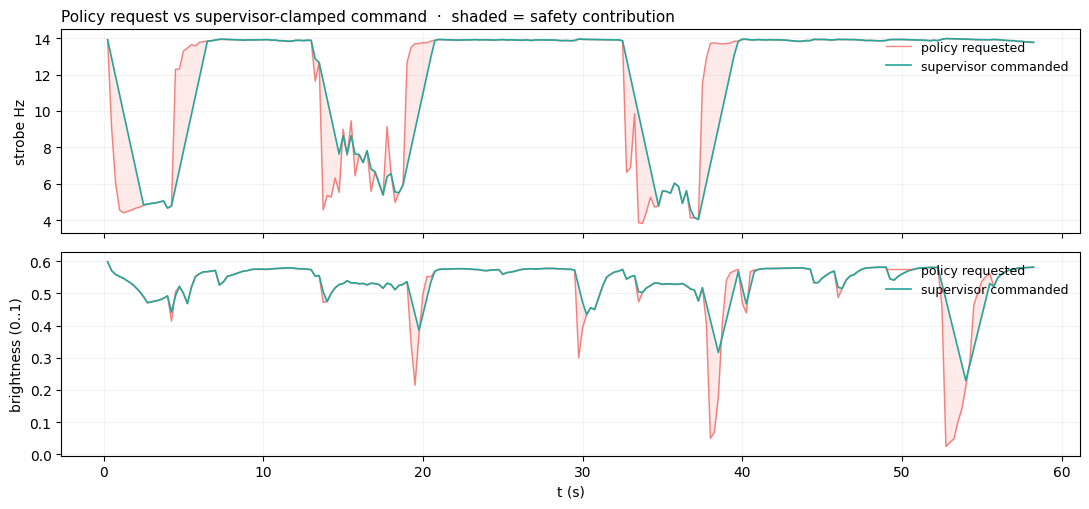

Per-axis supervisor contribution (|safe - request|, mean over 233 ticks):
  Δ frequency:   0.804 Hz   (max 7.10)
  Δ fill:        0.0000      (max 0.000)
  Δ brightness:  0.0188      (max 0.456)


In [4]:
if actions is None or len(actions) == 0:
    print('No agent_action.parquet - this session predates the action-logger '
          '(c. May 2026). Re-run the smoke script or any live session to populate.')
else:
    fig, axes = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True)

    # Frequency axis
    ax = axes[0]
    ax.plot(actions['t_s'], actions['request_freq_hz'], color='#EF5350',
            lw=1.0, alpha=0.7, label='policy requested')
    ax.plot(actions['t_s'], actions['safe_freq_hz'], color='#26A69A',
            lw=1.2, label='supervisor commanded')
    ax.fill_between(actions['t_s'], actions['request_freq_hz'],
                    actions['safe_freq_hz'], color='#EF5350', alpha=0.12)
    ax.set_ylabel('strobe Hz')
    ax.legend(loc='upper right', frameon=False, fontsize=9)
    ax.grid(alpha=0.15)
    ax.set_title('Policy request vs supervisor-clamped command  ·  '
                 'shaded = safety contribution', loc='left', fontsize=11)

    # Brightness axis
    ax = axes[1]
    ax.plot(actions['t_s'], actions['request_brightness'], color='#EF5350',
            lw=1.0, alpha=0.7, label='policy requested')
    ax.plot(actions['t_s'], actions['safe_brightness'], color='#26A69A',
            lw=1.2, label='supervisor commanded')
    ax.fill_between(actions['t_s'], actions['request_brightness'],
                    actions['safe_brightness'], color='#EF5350', alpha=0.12)
    ax.set_xlabel('t (s)')
    ax.set_ylabel('brightness (0..1)')
    ax.legend(loc='upper right', frameon=False, fontsize=9)
    ax.grid(alpha=0.15)

    fig.tight_layout(); plt.show()

    # Per-axis clamp magnitude
    df = actions.copy()
    df['Δ_freq'] = (df['safe_freq_hz'] - df['request_freq_hz']).abs()
    df['Δ_fill'] = (df['safe_fill'] - df['request_fill']).abs()
    df['Δ_brightness'] = (df['safe_brightness'] - df['request_brightness']).abs()
    print(f'Per-axis supervisor contribution (|safe - request|, mean over {len(df)} ticks):')
    print(f'  Δ frequency:   {df["Δ_freq"].mean():.3f} Hz   (max {df["Δ_freq"].max():.2f})')
    print(f'  Δ fill:        {df["Δ_fill"].mean():.4f}      (max {df["Δ_fill"].max():.3f})')
    print(f'  Δ brightness:  {df["Δ_brightness"].mean():.4f}      (max {df["Δ_brightness"].max():.3f})')

## 4. Safety-event timeline

Every safety-supervisor intervention written to `safety_events.jsonl`. Rug-plot at the top shows when each clamp class fired; counts table at the bottom summarises the breakdown. A clean session should have very few or zero `pse_guard` events (the catastrophic class); `ramp_limit` events are expected in the first few seconds as the agent ramps up from idle.

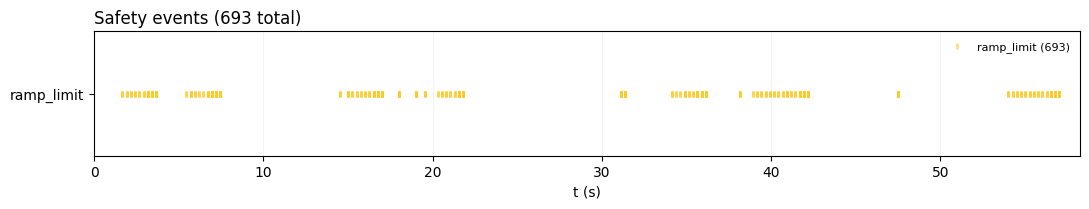


By kind / field:
kind        field       
ramp_limit  brightness      374
            frequency_hz    319

PSE-band guards fired: 0 / 693


In [5]:
if not safety:
    print('No safety_events.jsonl entries (the supervisor never had to clamp). '
          'For a real-hardware session this is good news; for a smoke run it '
          'usually means the action-decoder kept the policy inside the safe '
          'envelope (decode_action_for_deployment) without any clamp_for_safety '
          'follow-up.')
else:
    safety_df = pd.DataFrame(safety)
    safety_df['t_s'] = safety_df['t_ms'] / 1000.0
    KIND_COLOR = {
        'pse_guard':      '#EF5350',
        'ramp_limit':     '#FFCA28',
        'brightness_bounds': '#7E57C2',
        'fill_bounds':    '#5C6BC0',
        'freq_bounds':    '#26A69A',
        'disconnect':     '#EC407A',
    }
    kinds = list(safety_df['kind'].unique())
    fig, ax = plt.subplots(figsize=(11, max(2.2, 0.4 * len(kinds) + 1)))
    for i, k in enumerate(kinds):
        rows = safety_df[safety_df['kind'] == k]
        ax.scatter(rows['t_s'], [i] * len(rows), s=18,
                   color=KIND_COLOR.get(k, '#888'), label=f'{k} ({len(rows)})',
                   alpha=0.6, marker='|', linewidths=2)
    ax.set_yticks(range(len(kinds)))
    ax.set_yticklabels(kinds)
    ax.set_xlim(0, duration_s)
    ax.set_xlabel('t (s)')
    ax.set_title(f'Safety events ({len(safety_df)} total)', loc='left')
    ax.legend(loc='upper right', frameon=False, fontsize=8, ncol=2)
    ax.grid(alpha=0.15, axis='x')
    fig.tight_layout(); plt.show()

    print('\nBy kind / field:')
    print(safety_df.groupby(['kind', 'field']).size().to_string())
    pse = safety_df[safety_df['kind'] == 'pse_guard']
    print(f'\nPSE-band guards fired: {len(pse)} / {len(safety_df)}')
    assert len(pse) == 0 or pse['after'].max() < 14.0, (
        'pse_guard fired AND let an actuation through above 14 Hz - investigate')

## 5. Raw EEG sanity (only for sessions that recorded raw_eeg.csv)

First 4 s and last 4 s of the recorded raw EEG, channel 0 (occipital_alpha primary). For a real-hardware session this proves the BIOLISTENER ADC actually streamed data; for a sim session it proves the NMM TCP server's output was captured. Long dropouts / saturation here would invalidate every other plot above.

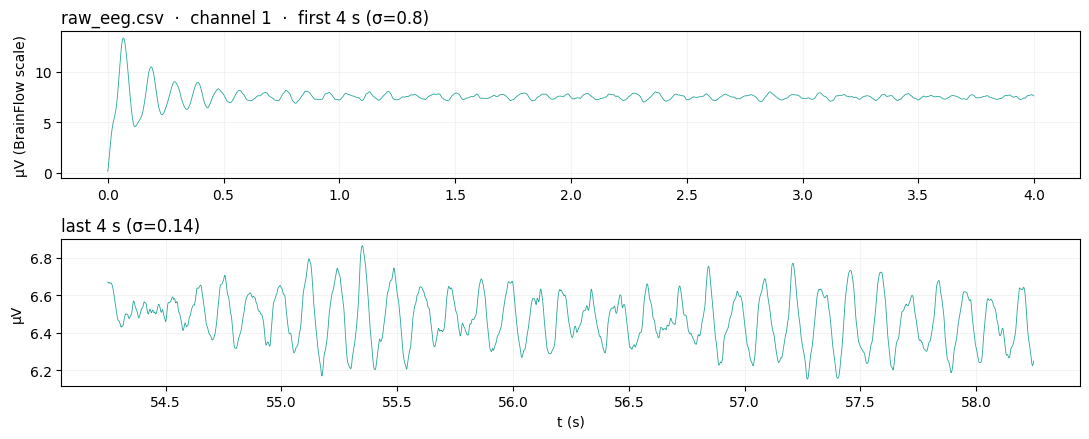

  raw_eeg.csv: 9 cols × 29125 samples ≈ 58.2 s @ 500 Hz
  reported session duration:  58.2 s


In [6]:
raw_csv = SESSION / 'raw_eeg.csv'
if not raw_csv.exists():
    print(f'No raw_eeg.csv - this {protocol.get("eeg_source", "?")} session ran '
          'before sim recording was wired (or hardware run pre-record).')
else:
    # BrainFlow CSV is tab-separated, no header. Rows = samples, cols = channels.
    raw = np.loadtxt(raw_csv, delimiter='\t').T   # -> (channels, samples)
    sr = 500   # BIOLISTENER default; matches eeg.sampling_rate in daemon_prod.yaml
    n_show = min(sr * 4, raw.shape[1] // 2)
    # Channel index 1 for BIOLISTENER is the first EEG channel
    # (channel 0 is timestamp). Pick the lowest-index non-zero-variance channel.
    ch_idx = 1
    for c in range(1, min(raw.shape[0], 16)):
        if raw[c].std() > 1e-9:
            ch_idx = c
            break
    t_head = np.arange(n_show) / sr
    t_tail = (raw.shape[1] - n_show + np.arange(n_show)) / sr

    fig, axes = plt.subplots(2, 1, figsize=(11, 4.5), sharey=False)
    axes[0].plot(t_head, raw[ch_idx, :n_show], color='#26A69A', lw=0.6)
    axes[0].set_title(f'raw_eeg.csv  ·  channel {ch_idx}  ·  first 4 s '
                       f'(σ={raw[ch_idx, :n_show].std():.2g})', loc='left')
    axes[0].set_ylabel('µV (BrainFlow scale)')
    axes[0].grid(alpha=0.15)
    axes[1].plot(t_tail, raw[ch_idx, -n_show:], color='#26A69A', lw=0.6)
    axes[1].set_title(f'last 4 s (σ={raw[ch_idx, -n_show:].std():.2g})',
                       loc='left')
    axes[1].set_xlabel('t (s)')
    axes[1].set_ylabel('µV')
    axes[1].grid(alpha=0.15)
    fig.tight_layout(); plt.show()

    n_samples = raw.shape[1]
    rec_s = n_samples / sr
    print(f'  raw_eeg.csv: {raw.shape[0]} cols × {n_samples} samples '
          f'≈ {rec_s:.1f} s @ {sr} Hz')
    print(f'  reported session duration:  {duration_s:.1f} s')
    drift = rec_s - duration_s
    if abs(drift) > 2.0:
        print(f'  ⚠ raw_eeg drift vs control tick clock: {drift:+.1f} s')

## 6. Tick-budget compute histogram

Per-tick compute time (excluding the asyncio sleep). The 250 ms line is the 4 Hz budget; the population should sit well to the left of it. Outliers above the line indicate WS/Mongo/audio jitter.

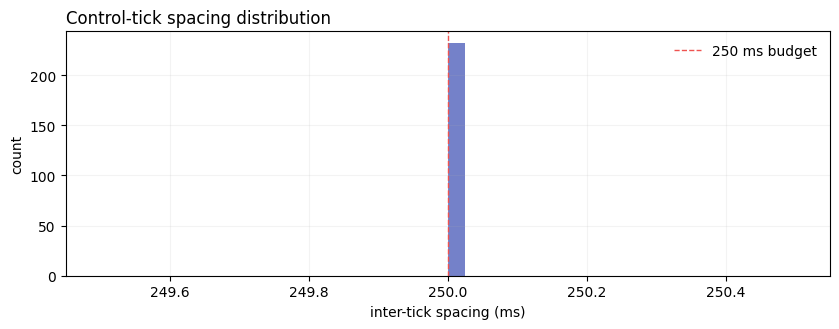

  median spacing: 250 ms  ·  p95: 250 ms  ·  max: 250 ms


In [7]:
# Tick-budget data isn't separately persisted - reconstruct an approximation
# from the t_ms grid: actual inter-tick spacing vs the nominal 250 ms.
if actions is not None and len(actions) > 1:
    spacings_ms = actions['t_ms'].diff().dropna()
    fig, ax = plt.subplots(figsize=(8.5, 3.4))
    ax.hist(spacings_ms, bins=40, color='#5C6BC0', alpha=0.85)
    ax.axvline(250, color='#EF5350', lw=1.0, linestyle='--', label='250 ms budget')
    ax.set_xlabel('inter-tick spacing (ms)')
    ax.set_ylabel('count')
    ax.set_title('Control-tick spacing distribution', loc='left')
    ax.legend(loc='upper right', frameon=False)
    ax.grid(alpha=0.15)
    fig.tight_layout(); plt.show()
    print(f'  median spacing: {spacings_ms.median():.0f} ms  ·  '
          f'p95: {np.percentile(spacings_ms, 95):.0f} ms  ·  '
          f'max: {spacings_ms.max():.0f} ms')
else:
    print('No action log - cannot reconstruct tick spacing.')